# Lab 3.2 - Student Notebook

## Overview

This lab is a continuation of the guided labs in Module 3. 

## Introducing the business scenario

You work for a healthcare provider, and want to improve the detection of abnormalities in orthopedic patients. 

You are tasked with solving this problem by using machine learning (ML). You have access to a dataset that contains six biomechanical features and a target of *normal* or *abnormal*. You can use this dataset to train an ML model to predict if a patient will have an abnormality.

## About this dataset
This biomedical dataset was built by Dr. Henrique da Mota during a medical residence period in the Group of Applied Research in Orthopaedics (GARO) of the Centre Médico-Chirurgical de Réadaptation des Massues, Lyon, France. The data has been organized in two different, but related, classification tasks. 

The first task consists in classifying patients as belonging to one of three categories: 

- *Normal* (100 patients)
- *Disk Hernia* (60 patients)
- *Spondylolisthesis* (150 patients)

For the second task, the categories *Disk Hernia* and *Spondylolisthesis* were merged into a single category that is labeled as *abnormal*. Thus, the second task consists in classifying patients as belonging to one of two categories: *Normal* (100 patients) or *Abnormal* (210 patients).


## Attribute information

Each patient is represented in the dataset by six biomechanical attributes that are derived from the shape and orientation of the pelvis and lumbar spine (in this order): 

- Pelvic incidence
- Pelvic tilt
- Lumbar lordosis angle
- Sacral slope
- Pelvic radius
- Grade of spondylolisthesis

The following convention is used for the class labels: 
- DH (Disk Hernia)
- Spondylolisthesis (SL)
- Normal (NO) 
- Abnormal (AB)


For more information about this dataset, see the [Vertebral Column dataset webpage](http://archive.ics.uci.edu/ml/datasets/Vertebral+Column).

## Dataset attributions
This dataset was obtained from:
Dua, D. and Graff, C. (2019). UCI Machine Learning Repository (http://archive.ics.uci.edu/ml). Irvine, CA: University of California, School of Information and Computer Science.


# Lab setup
Because this solution is split across several labs in this module, you must run the following cells so that you can load the data:

## Importing the data

In [251]:
import warnings, requests, zipfile, io
warnings.simplefilter('ignore')
import pandas as pd
from scipy.io import arff

In [252]:
f_zip = 'http://archive.ics.uci.edu/static/public/320/student+performance.zip'
r = requests.get(f_zip, stream=True)
Vertebral_zip = zipfile.ZipFile(io.BytesIO(r.content))
Vertebral_zip.extractall()

In [253]:
data = arff.loadarff('column_2C_weka.arff')
df = pd.DataFrame(data[0])

# Step 1: Exploring the data
You will start by looking at the data in the dataset. 

To get the most out of this lab, carefully read the instructions and code before you run the cells. Take time to experiment!

First, you will use **shape** to examine the number of rows and columns

In [254]:
df.shape

(310, 7)

You will now get a list of the columns.

In [255]:
df.columns

Index(['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle',
       'sacral_slope', 'pelvic_radius', 'degree_spondylolisthesis', 'class'],
      dtype='object')

You can see the six biomechanical features, and the target column is named *class*.

What column types do you have?

In [256]:
df.dtypes

pelvic_incidence            float64
pelvic_tilt                 float64
lumbar_lordosis_angle       float64
sacral_slope                float64
pelvic_radius               float64
degree_spondylolisthesis    float64
class                        object
dtype: object

You have six floats for the biomechanical features, but the target is a class.

To look at the statistics for the first column, you can use the **describe** function.

**Challenge Task:** Try updating the code in the previous cell to view the statistics of other features. Which features have outliers that you might want to examine?

In [257]:
for col in df.columns[:-1]:
    print(f"Statistics for {col}:")
    print(df[col].describe())
    print()

Statistics for pelvic_incidence:
count    310.000000
mean      60.496653
std       17.236520
min       26.147921
25%       46.430294
50%       58.691038
75%       72.877696
max      129.834041
Name: pelvic_incidence, dtype: float64

Statistics for pelvic_tilt:
count    310.000000
mean      17.542822
std       10.008330
min       -6.554948
25%       10.667069
50%       16.357689
75%       22.120395
max       49.431864
Name: pelvic_tilt, dtype: float64

Statistics for lumbar_lordosis_angle:
count    310.000000
mean      51.930930
std       18.554064
min       14.000000
25%       37.000000
50%       49.562398
75%       63.000000
max      125.742385
Name: lumbar_lordosis_angle, dtype: float64

Statistics for sacral_slope:
count    310.000000
mean      42.953831
std       13.423102
min       13.366931
25%       33.347122
50%       42.404912
75%       52.695888
max      121.429566
Name: sacral_slope, dtype: float64

Statistics for pelvic_radius:
count    310.000000
mean     117.920655
std   

Because this dataset only has six features, you can display the statistics of each feature by running **describe** on the entire DataFrame.

In [258]:
df.describe()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
count,310.000000,310.000000,310.000000,310.000000,310.000000,310.000000
mean,60.496653,17.542822,51.930930,42.953831,117.920655,26.296694
std,17.236520,10.008330,18.554064,13.423102,13.317377,37.559027
min,26.147921,-6.554948,14.000000,13.366931,70.082575,-11.058179
25%,46.430294,10.667069,37.000000,33.347122,110.709196,1.603727
50%,58.691038,16.357689,49.562398,42.404912,118.268178,11.767934
75%,72.877696,22.120395,63.000000,52.695888,125.467674,41.287352
max,129.834041,49.431864,125.742385,121.429566,163.071041,418.543082


**Question:** Are there any features that aren't well-distributed? Are there any features with outliers that you want to look at? Does it look like there might be any correlations between features?

R// La variable **degree_spondylolisthesis** tiene una distribución muy desigual. Una distribución sesgada (asimétrica) cuando se compara la media (26.3) y el percentil 50% (mediana 11.8) con el resto de los datos. Esto indica que hay valores extremos que pueden afectar significativamente el modelo.
En el valor del 75% (41.3) a maximo (418.5) es enorme. Confirma la presencia de valores atípicos (outliers) muy extremos en el lado alto. Definitivamente querrías investigar esos casos. Para observar mejor la correlacciones se necesario tener una matriz de correlación que se sacar por medio de df.corr(). 


It's not always easy to make observations when you look only at numbers, so you will now plot these values.

<Axes: >

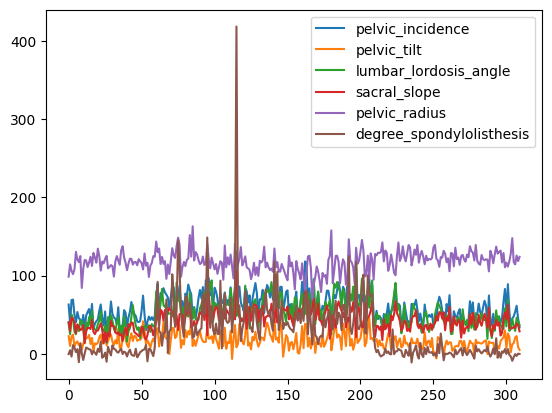

In [259]:
import matplotlib.pyplot as plt
%matplotlib inline
df.plot()

You will now plot the distribution of the values for each feature by using a *density or kernel density estimate (KDE) plot*.

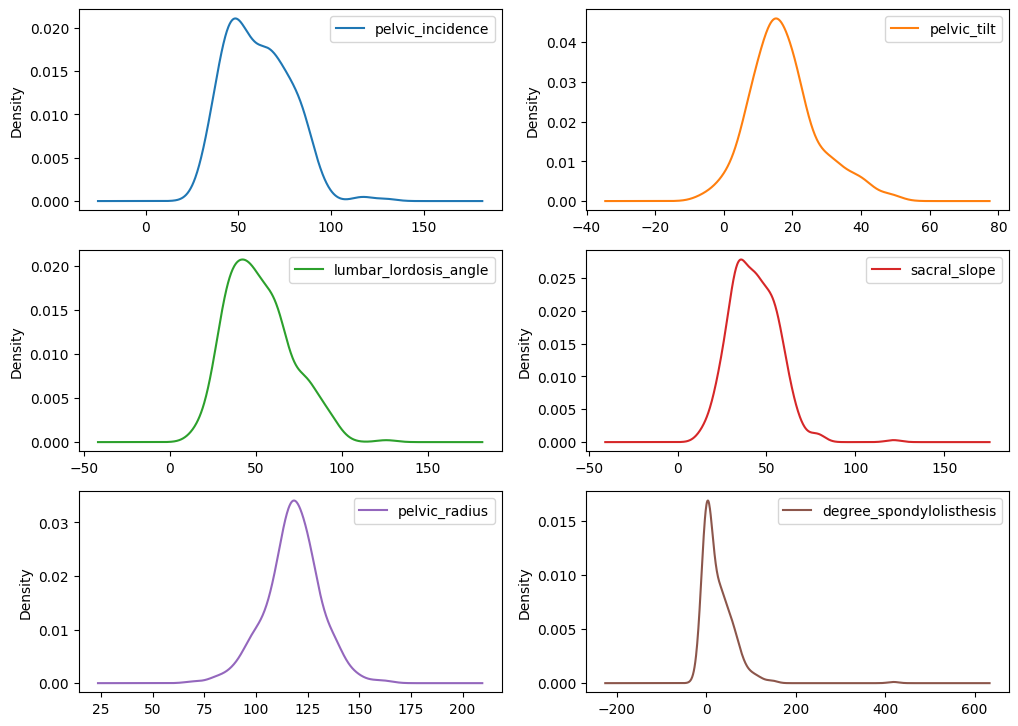

In [260]:
df.plot(kind='density',subplots=True,layout=(4,2),figsize=(12,12),sharex=False)
plt.show()

Do any of the visualizations stand out?

### Investigating degree_spondylolisthesis
You will now investigate **degree_spondylolisthesis**:

Start with the *density plot*, which if you recall, shows the *distribution of the values*.

<Axes: ylabel='Density'>

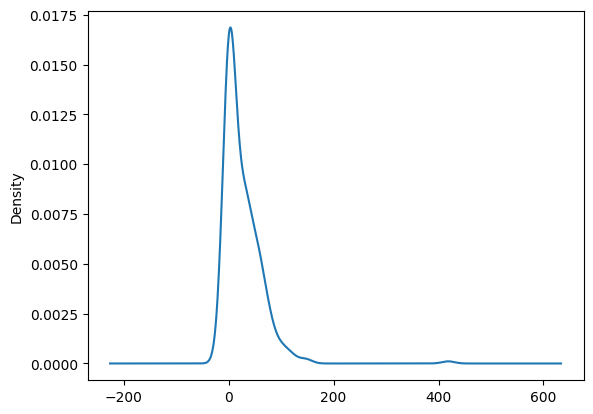

In [261]:
df['degree_spondylolisthesis'].plot.density()

A density plot smooths out the curve. It looks like there might be an increase around **400**. Visualize the data with a *histogram*.

<Axes: ylabel='Frequency'>

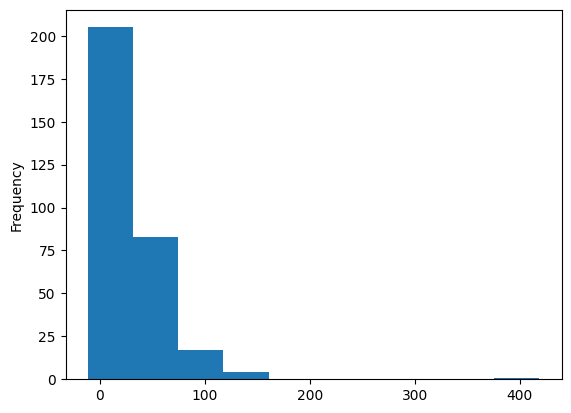

In [262]:
df['degree_spondylolisthesis'].plot.hist()

By using a *box plot*, you can see if there any outliers.

<Axes: >

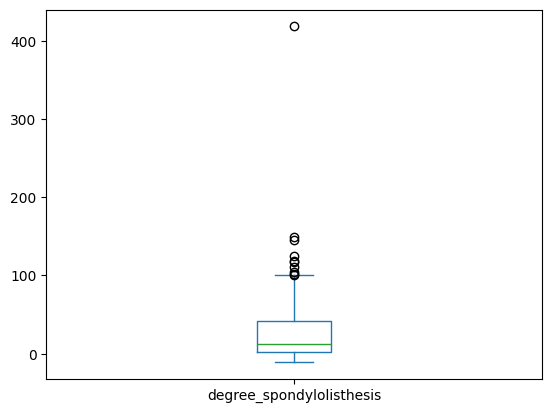

In [263]:
df['degree_spondylolisthesis'].plot.box()

You can see a small increase around **400**. Sometimes, outliers like this can throw off training models. The only way to find out would be to test the model both with and without the outliers, and compare the models' scores. However, this is a task for a later lab.

You can see from the box plot that there seems to be a cluster above what *looks like* the maximum. Is there a correlation between those data points and the target?

Before you can look for a correlation, you will examine the target more.

### Analyzing the target

First, what kind of distribution do you have?

In [264]:
df['class'].value_counts()

class
b'Abnormal'    210
b'Normal'      100
Name: count, dtype: int64

It loks like you have about 1/3 *Normal* and 2/3 *Abnormal*. This result should be fine, but if you could get more data, you would want to try and balance the numbers more. 

The class values aren't going to work for your ML model, so you will convert this column to a numeric value. You can use a *mapper* for this task.

In [265]:
class_mapper = {b'Abnormal':1,b'Normal':0}
df['class']=df['class'].replace(class_mapper)

Now, you can plot the *degree_spondylolisthesis* against the target.

<Axes: xlabel='class', ylabel='degree_spondylolisthesis'>

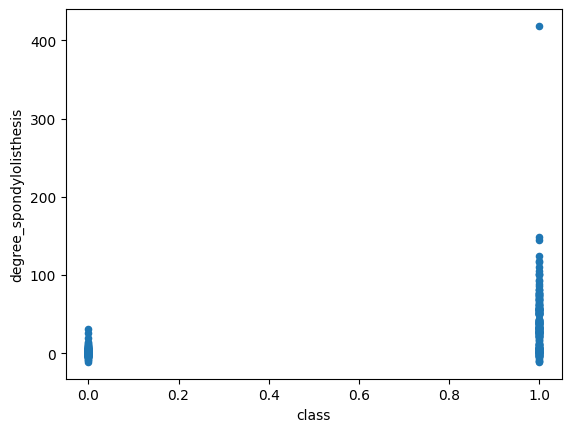

In [266]:
df.plot.scatter(y='degree_spondylolisthesis',x='class')

What do you see?

Though there appears to be a link between the high values and the abnormalities, there are also many values that are in the same range. So, there could be a correlation, but it's worth taking a closer look at the data.

**Challenge Task:** By using the previous cells, determine how the values of other features correspond against the target.

<Axes: xlabel='class', ylabel='lumbar_lordosis_angle'>

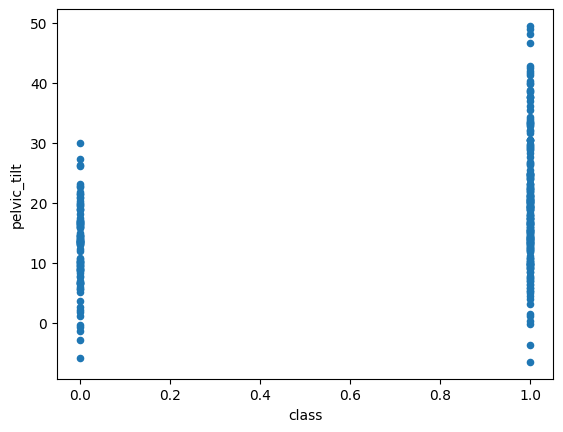

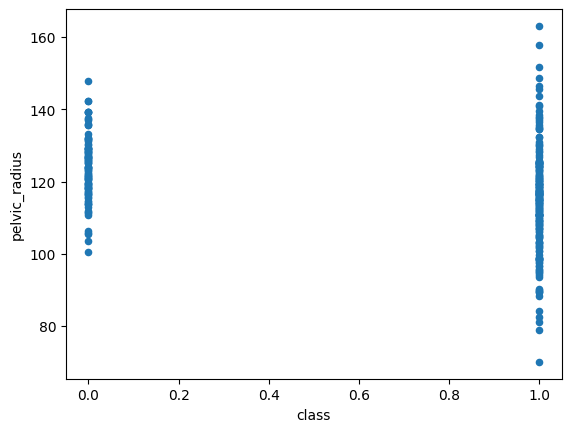

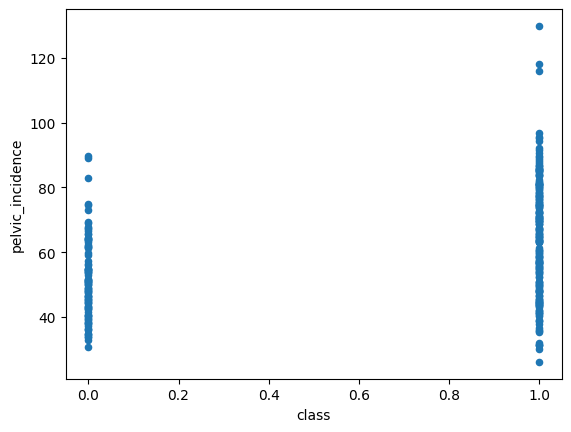

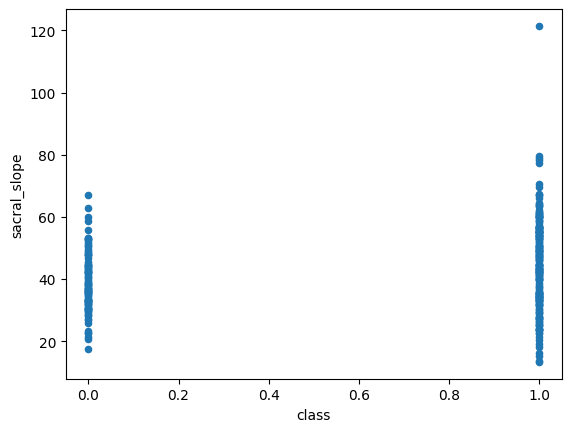

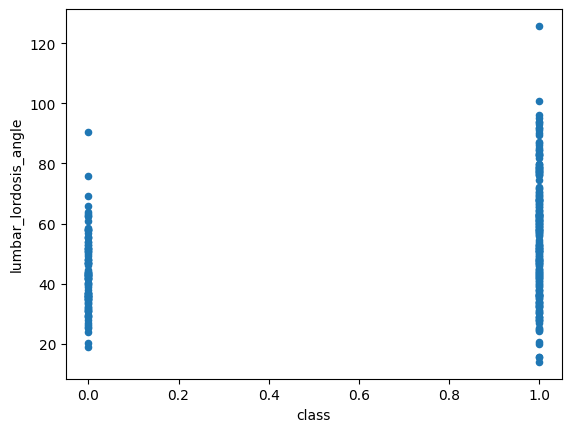

In [267]:
# By using the previous cells, determine how the values of other features correspond against the target.
df.plot.scatter(y='pelvic_tilt', x='class')
df.plot.scatter(y='pelvic_radius', x='class')
df.plot.scatter(y='pelvic_incidence', x='class')
df.plot.scatter(y='sacral_slope', x='class')
df.plot.scatter(y='lumbar_lordosis_angle', x='class')



### Visualizing multiple variables

As the previous steps demonstrate, visualizations can be very powerful. Sometimes, you will want to analyze multiple data points. You can do this by using *groupby*.

Plotting out the features for both *Abnormal* and *Normal* values side by side might help you observe any other differences.

0         Axes(0.1,0.15;0.363636x0.75)
1    Axes(0.536364,0.15;0.363636x0.75)
dtype: object

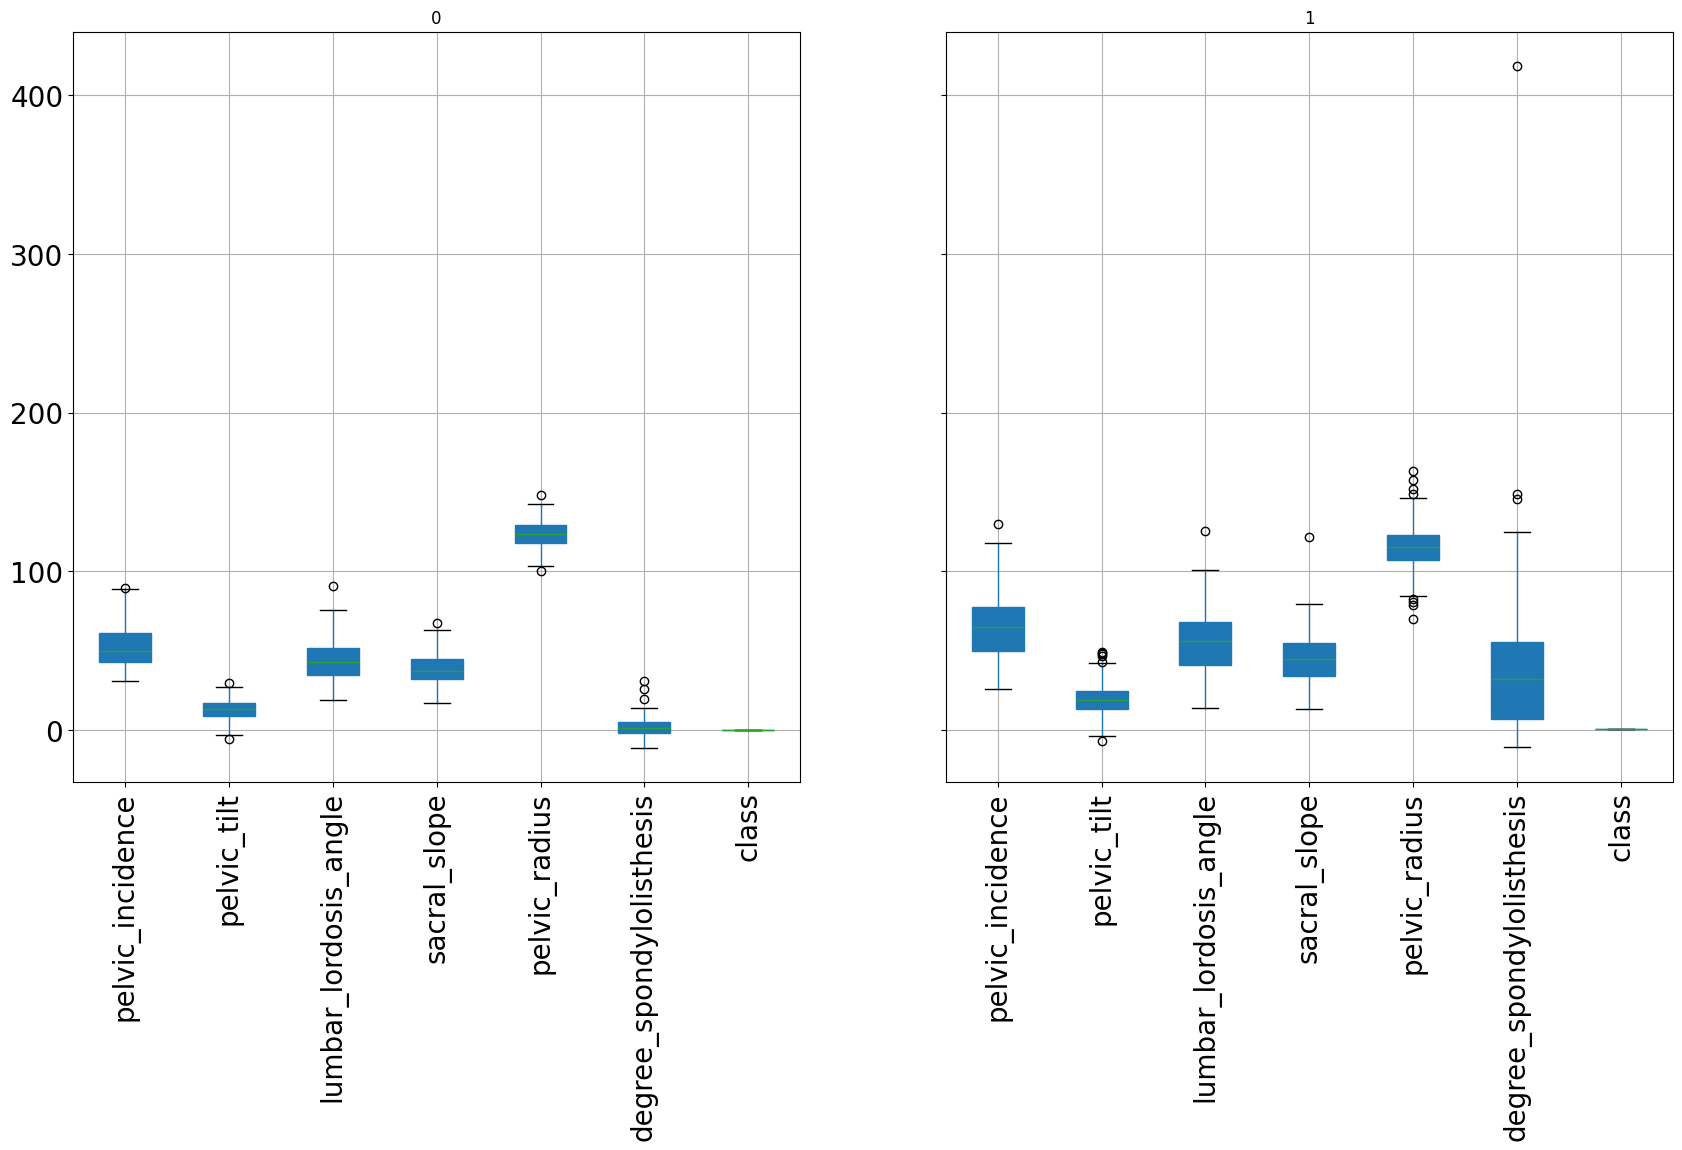

In [268]:
df.groupby('class').boxplot(fontsize=20,rot=90,figsize=(20,10),patch_artist=True)

Confirma que los outliers no eran errores, sino casos severos de la Clase 1. Además, muestra que los pacientes de Clase 1 no solo tienen un degree_spondylolisthesis más alto, sino que también tienen, en promedio:

- Mayor pelvic_incidence
- Mayor pelvic_tilt
- Menor sacral_slope
- Menor pelvic_radius

Using the **corr** function, you can create a correlation matrix for the entire dataset.

In [269]:
# Convert class column to numeric values
class_mapper_3c = {b'Hernia': 1, b'Spondylolisthesis': 2, b'Normal': 0}
df['class'] = df['class'].replace(class_mapper_3c)

corr_matrix = df.corr()
corr_matrix["class"].sort_values(ascending=False)

class                       1.000000
degree_spondylolisthesis    0.443687
pelvic_incidence            0.353336
pelvic_tilt                 0.326063
lumbar_lordosis_angle       0.312484
sacral_slope                0.210602
pelvic_radius              -0.309857
Name: class, dtype: float64

You can also plot out this data.

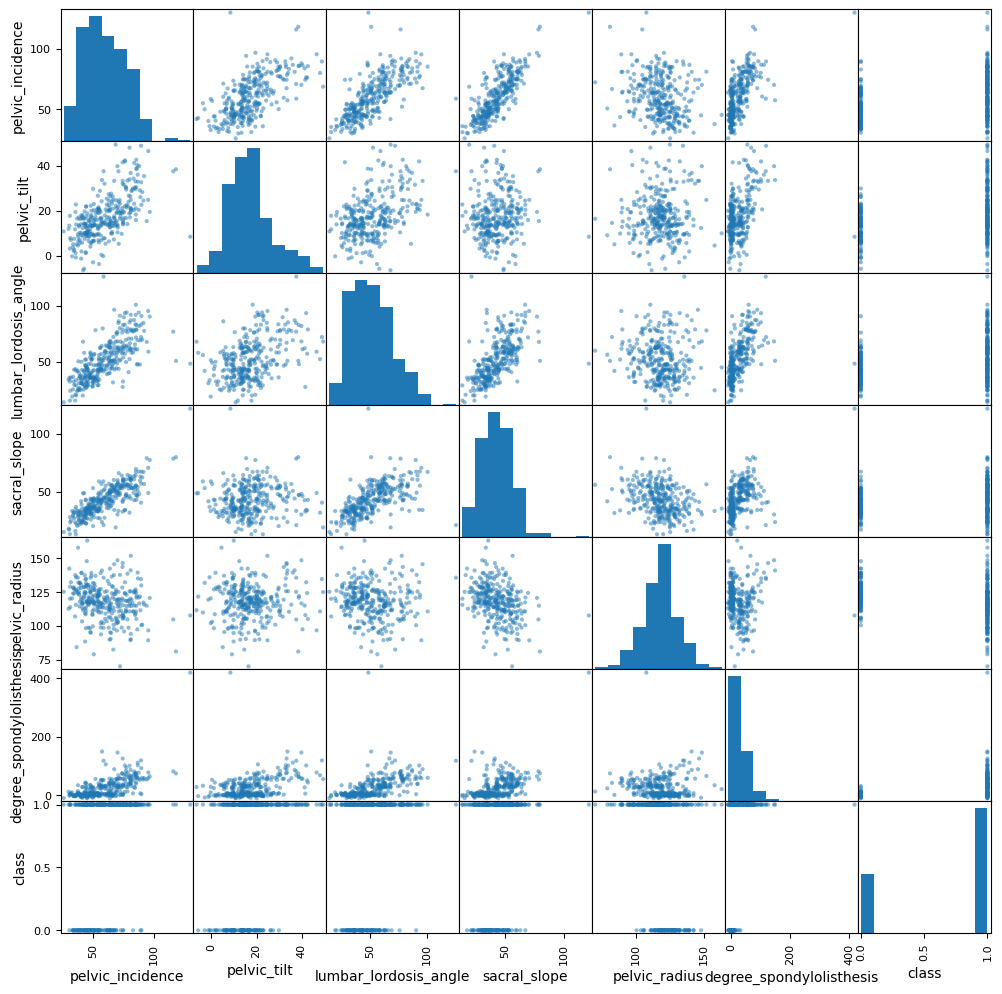

In [270]:
pd.plotting.scatter_matrix(df,figsize=(12,12))
plt.show()

By using **seaborn**, you can visualize the correlation as a *heatmap*.

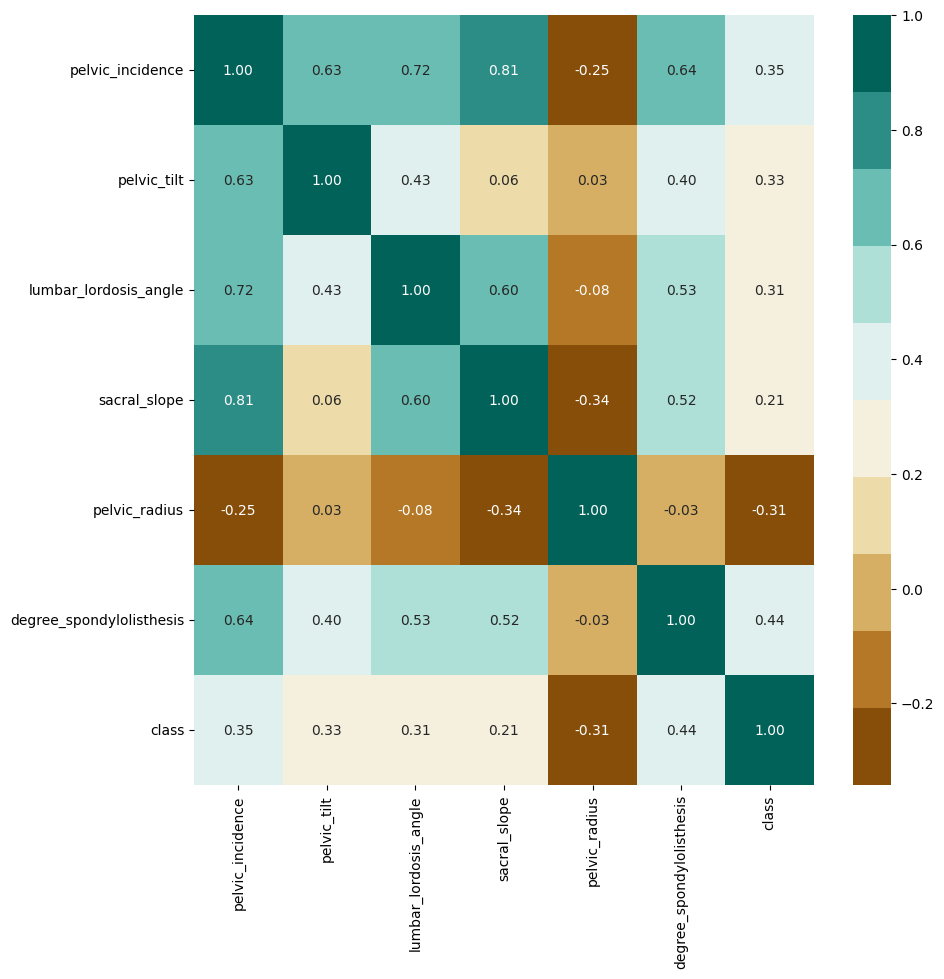

In [271]:
import seaborn as sns
# Plot figsize
fig, ax = plt.subplots(figsize=(10, 10))
# Generate Color Map
# colormap = sns.diverging_palette(220, 10, as_cmap=True)
colormap = sns.color_palette("BrBG", 10)
# Generate Heat Map, allow annotations and place floats in map

sns.heatmap(corr_matrix, cmap=colormap, annot=True, fmt=".2f")
#ax.set_yticklabels(column_names);
plt.show()

**Challenge task:** Find other data from the UCI Machine Learning Repository.  Using the previous code for reference, go explore!


This data approach student achievement in secondary education of two Portuguese schools. The data attributes include student grades, demographic, social and school related features) and it was collected by using school reports and questionnaires. Two datasets are provided regarding the performance in two distinct subjects: Mathematics (mat) and Portuguese language (por). In [Cortez and Silva, 2008], the two datasets were modeled under binary/five-level classification and regression tasks. Important note: the target attribute G3 has a strong correlation with attributes G2 and G1. This occurs because G3 is the final year grade (issued at the 3rd period), while G1 and G2 correspond to the 1st and 2nd period grades. It is more difficult to predict G3 without G2 and G1, but such prediction is much more useful (see paper source for more details).

http://archive.ics.uci.edu/dataset/320/student+performance

# Attributes for both student-mat.csv (Math course) and student-por.csv (Portuguese language course) datasets:
- 1 school - student's school (binary: "GP" - Gabriel Pereira or "MS" - Mousinho da Silveira)
- 2 sex - student's sex (binary: "F" - female or "M" - male)
- 3 age - student's age (numeric: from 15 to 22)
- 4 address - student's home address type (binary: "U" - urban or "R" - rural)
- 5 famsize - family size (binary: "LE3" - less or equal to 3 or "GT3" - greater than 3)
- 6 Pstatus - parent's cohabitation status (binary: "T" - living together or "A" - apart)
- 7 Medu - mother's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
- 8 Fedu - father's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
- 9 Mjob - mother's job (nominal: "teacher", "health" care related, civil "services" (e.g. administrative or police), "at_home" or "other")
- 10 Fjob - father's job (nominal: "teacher", "health" care related, civil "services" (e.g. administrative or police), "at_home" or "other")
- 11 reason - reason to choose this school (nominal: close to "home", school "reputation", "course" preference or "other")
- 12 guardian - student's guardian (nominal: "mother", "father" or "other")
- 13 traveltime - home to school travel time (numeric: 1 - <15 min., 2 - 15 to 30 min., 3 - 30 min. to 1 hour, or 4 - >1 hour)
- 14 studytime - weekly study time (numeric: 1 - <2 hours, 2 - 2 to 5 hours, 3 - 5 to 10 hours, or 4 - >10 hours)
- 15 failures - number of past class failures (numeric: n if 1<=n<3, else 4)
- 16 schoolsup - extra educational support (binary: yes or no)
- 17 famsup - family educational support (binary: yes or no)
- 18 paid - extra paid classes within the course subject (Math or Portuguese) (binary: yes or no)
- 19 activities - extra-curricular activities (binary: yes or no)
- 20 nursery - attended nursery school (binary: yes or no)
- 21 higher - wants to take higher education (binary: yes or no)
- 22 internet - Internet access at home (binary: yes or no)
- 23 romantic - with a romantic relationship (binary: yes or no)
- 24 famrel - quality of family relationships (numeric: from 1 - very bad to 5 - excellent)
- 25 freetime - free time after school (numeric: from 1 - very low to 5 - very high)
- 26 goout - going out with friends (numeric: from 1 - very low to 5 - very high)
- 27 Dalc - workday alcohol consumption (numeric: from 1 - very low to 5 - very high)
- 28 Walc - weekend alcohol consumption (numeric: from 1 - very low to 5 - very high)
- 29 health - current health status (numeric: from 1 - very bad to 5 - very good)
- 30 absences - number of school absences (numeric: from 0 to 93)

# these grades are related with the course subject, Math or Portuguese:
- 31 G1 - first period grade (numeric: from 0 to 20)
- 31 G2 - second period grade (numeric: from 0 to 20)
- 32 G3 - final grade (numeric: from 0 to 20, output target)

Additional note: there are several (382) students that belong to both datasets . 
These students can be identified by searching for identical attributes
that characterize each student, as shown in the annexed R file.


In [272]:
f_zip = 'http://archive.ics.uci.edu/static/public/320/student+performance.zip'
r = requests.get(f_zip, stream=True)
Vertebral_zip = zipfile.ZipFile(io.BytesIO(r.content))
Vertebral_zip.extractall()
Vertebral_zip = zipfile.ZipFile("student.zip")
Vertebral_zip.extractall()



In [273]:
df = pd.read_csv('student-mat.csv', sep=';') # usamos el dataset de grupo de matematicas

#el atributo objetivo G3 presenta una fuerte correlación con los atributos G2 y G1. 
# Esto se debe a que G3 es la calificación final (otorgada en el tercer periodo)
# mientras que G1 y G2 corresponden a las calificaciones del primer y segundo periodo
# vamos a ignorar tambien G2 y G1 para darle mas sentido al problema
df  = df.drop(columns=["G1", "G2", "Walc", "Dalc", "studytime", "health", "traveltime", "famrel", "Fedu", "freetime"], errors="ignore") ## esto se hizo luego de ver la datos y se observa que redundacia y sesgos fuertes (fuga de datos)
df

,school,sex,age,address,famsize,Pstatus,Medu,Mjob,Fjob,reason,...,famsup,paid,activities,nursery,higher,internet,romantic,goout,absences,G3
0,GP,F,18,U,GT3,A,4,at_home,teacher,course,...,no,no,no,yes,yes,no,no,4,6,6
1,GP,F,17,U,GT3,T,1,at_home,other,course,...,yes,no,no,no,yes,yes,no,3,4,6
2,GP,F,15,U,LE3,T,1,at_home,other,other,...,no,yes,no,yes,yes,yes,no,2,10,10
3,GP,F,15,U,GT3,T,4,health,services,home,...,yes,yes,yes,yes,yes,yes,yes,2,2,15
4,GP,F,16,U,GT3,T,3,other,other,home,...,yes,yes,no,yes,yes,no,no,2,4,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,services,services,course,...,yes,yes,no,yes,yes,no,no,4,11,9
391,MS,M,17,U,LE3,T,3,services,services,course,...,no,no,no,no,yes,yes,no,5,3,16
392,MS,M,21,R,GT3,T,1,other,other,course,...,no,no,no,no,yes,no,no,3,3,7
393,MS,M,18,R,LE3,T,3,services,other,course,...,no,no,no,no,yes,yes,no,1,0,10


In [274]:
df.shape

(395, 23)

In [275]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Mjob',
       'Fjob', 'reason', 'guardian', 'failures', 'schoolsup', 'famsup', 'paid',
       'activities', 'nursery', 'higher', 'internet', 'romantic', 'goout',
       'absences', 'G3'],
      dtype='object')

In [276]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Mjob        395 non-null    object
 8   Fjob        395 non-null    object
 9   reason      395 non-null    object
 10  guardian    395 non-null    object
 11  failures    395 non-null    int64 
 12  schoolsup   395 non-null    object
 13  famsup      395 non-null    object
 14  paid        395 non-null    object
 15  activities  395 non-null    object
 16  nursery     395 non-null    object
 17  higher      395 non-null    object
 18  internet    395 non-null    object
 19  romantic    395 non-null    object
 20  goout     

In [277]:
df.describe()

,age,Medu,failures,goout,absences,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,0.334177,3.108861,5.708861,10.415190
std,1.276043,1.094735,0.743651,1.113278,8.003096,4.581443
min,15.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,16.000000,2.000000,0.000000,2.000000,0.000000,8.000000
50%,17.000000,3.000000,0.000000,3.000000,4.000000,11.000000
75%,18.000000,4.000000,0.000000,4.000000,8.000000,14.000000
max,22.000000,4.000000,3.000000,5.000000,75.000000,20.000000


<Axes: >

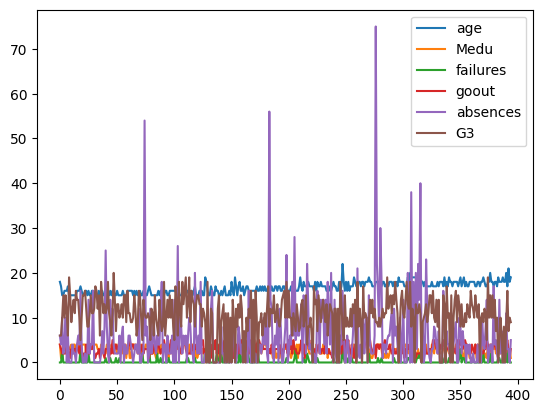

In [278]:
df.plot()

In [279]:
for col in df.columns[:-1]:
    print(f"Statistics for {col}:")
    print(df[col].describe())
    print()

Statistics for school:
count     395
unique      2
top        GP
freq      349
Name: school, dtype: object

Statistics for sex:
count     395
unique      2
top         F
freq      208
Name: sex, dtype: object

Statistics for age:
count    395.000000
mean      16.696203
std        1.276043
min       15.000000
25%       16.000000
50%       17.000000
75%       18.000000
max       22.000000
Name: age, dtype: float64

Statistics for address:
count     395
unique      2
top         U
freq      307
Name: address, dtype: object

Statistics for famsize:
count     395
unique      2
top       GT3
freq      281
Name: famsize, dtype: object

Statistics for Pstatus:
count     395
unique      2
top         T
freq      354
Name: Pstatus, dtype: object

Statistics for Medu:
count    395.000000
mean       2.749367
std        1.094735
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        4.000000
Name: Medu, dtype: float64

Statistics for Mjob:
count       395
unique 

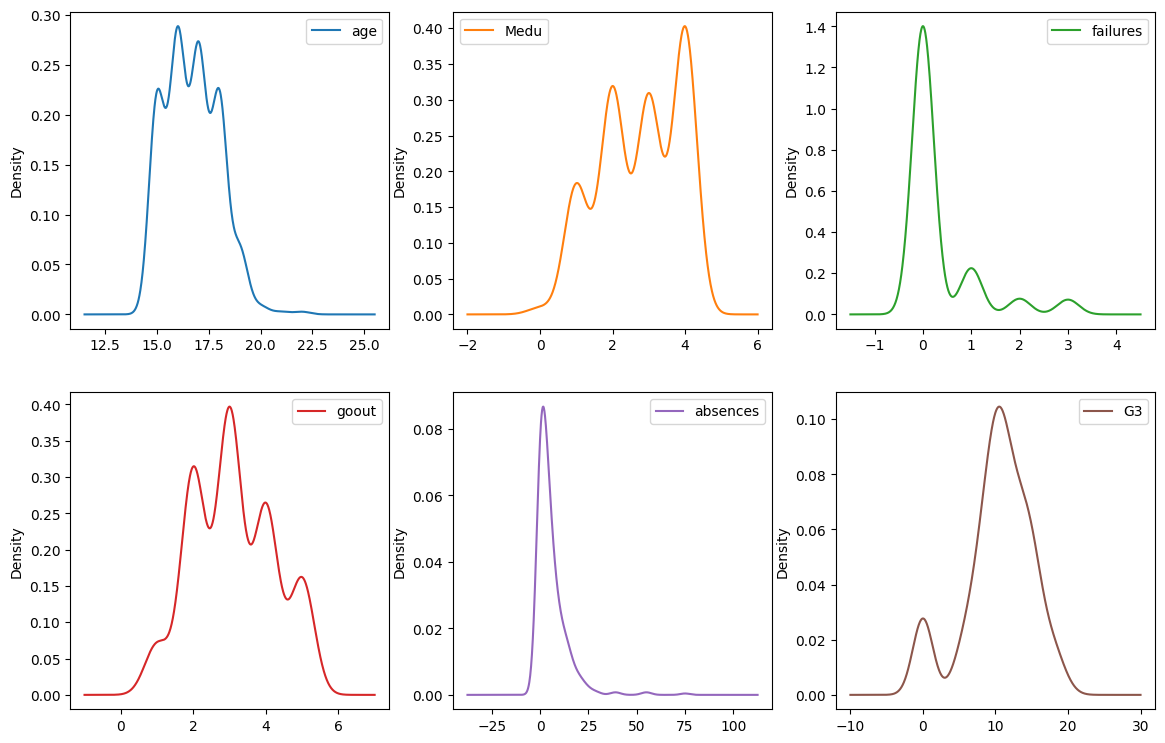

In [280]:
df.plot(kind='density', subplots=True, layout=(3,3), figsize=(14,14), sharex=False)
plt.show()

count    395.000000
mean       0.334177
std        0.743651
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        3.000000
Name: failures, dtype: float64


<Axes: ylabel='Density'>

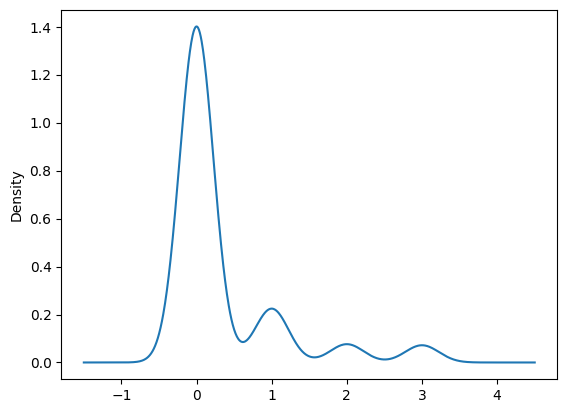

In [281]:
print(df['failures'].describe())
df['failures'].plot.density()


count    395.000000
mean       5.708861
std        8.003096
min        0.000000
25%        0.000000
50%        4.000000
75%        8.000000
max       75.000000
Name: absences, dtype: float64


<Axes: ylabel='Density'>

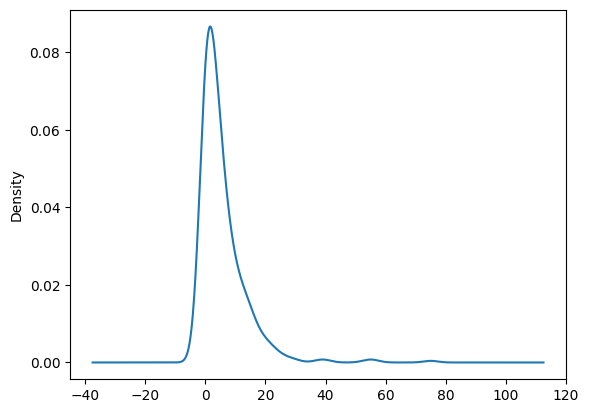

In [282]:
print(df['absences'].describe())
df['absences'].plot.density()


<Axes: ylabel='Frequency'>

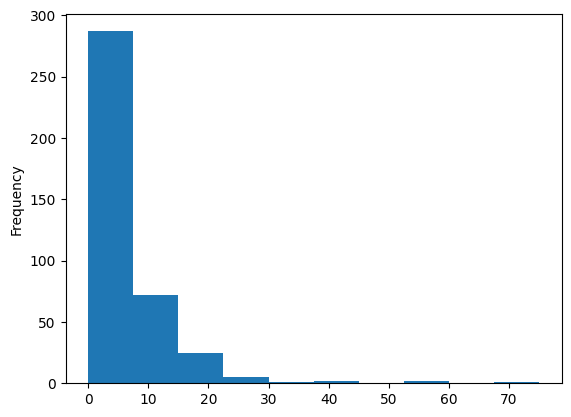

In [283]:
df['absences'].plot.hist()

<Axes: ylabel='Frequency'>

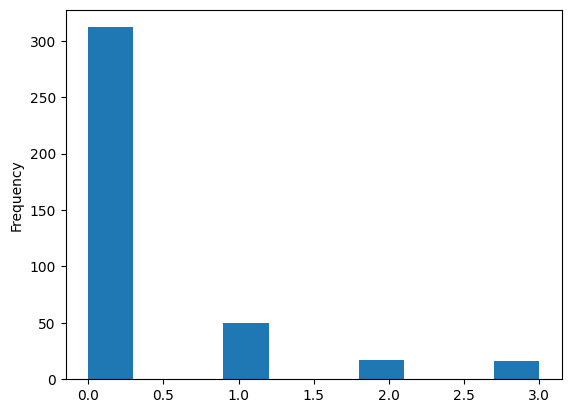

In [284]:
df['failures'].plot.hist()

<Axes: xlabel='G3', ylabel='age'>

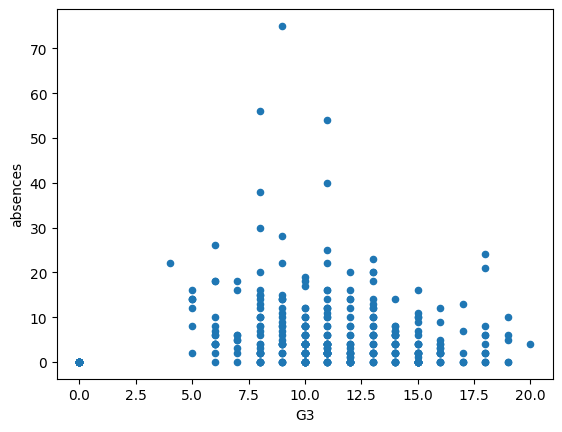

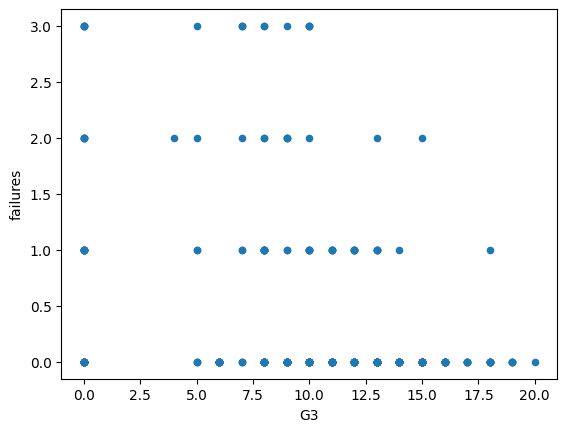

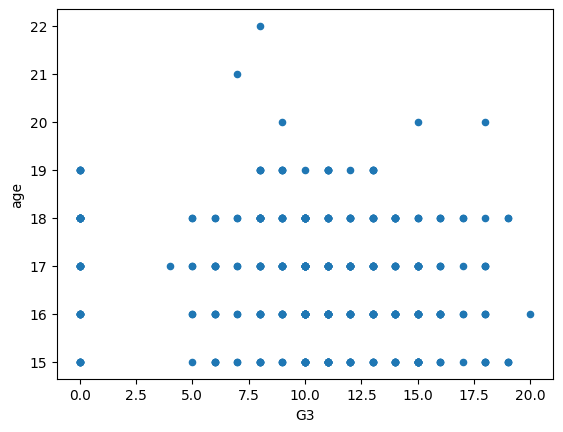

In [285]:
df.plot.scatter(y='absences', x='G3')
df.plot.scatter(y='failures', x='G3')
df.plot.scatter(y='age', x='G3')

0           Axes(0.1,0.77069;0.173913x0.12931)
4      Axes(0.308696,0.77069;0.173913x0.12931)
5      Axes(0.517391,0.77069;0.173913x0.12931)
6      Axes(0.726087,0.77069;0.173913x0.12931)
7          Axes(0.1,0.615517;0.173913x0.12931)
8     Axes(0.308696,0.615517;0.173913x0.12931)
9     Axes(0.517391,0.615517;0.173913x0.12931)
10    Axes(0.726087,0.615517;0.173913x0.12931)
11         Axes(0.1,0.460345;0.173913x0.12931)
12    Axes(0.308696,0.460345;0.173913x0.12931)
13    Axes(0.517391,0.460345;0.173913x0.12931)
14    Axes(0.726087,0.460345;0.173913x0.12931)
15         Axes(0.1,0.305172;0.173913x0.12931)
16    Axes(0.308696,0.305172;0.173913x0.12931)
17    Axes(0.517391,0.305172;0.173913x0.12931)
18    Axes(0.726087,0.305172;0.173913x0.12931)
19             Axes(0.1,0.15;0.173913x0.12931)
20        Axes(0.308696,0.15;0.173913x0.12931)
dtype: object

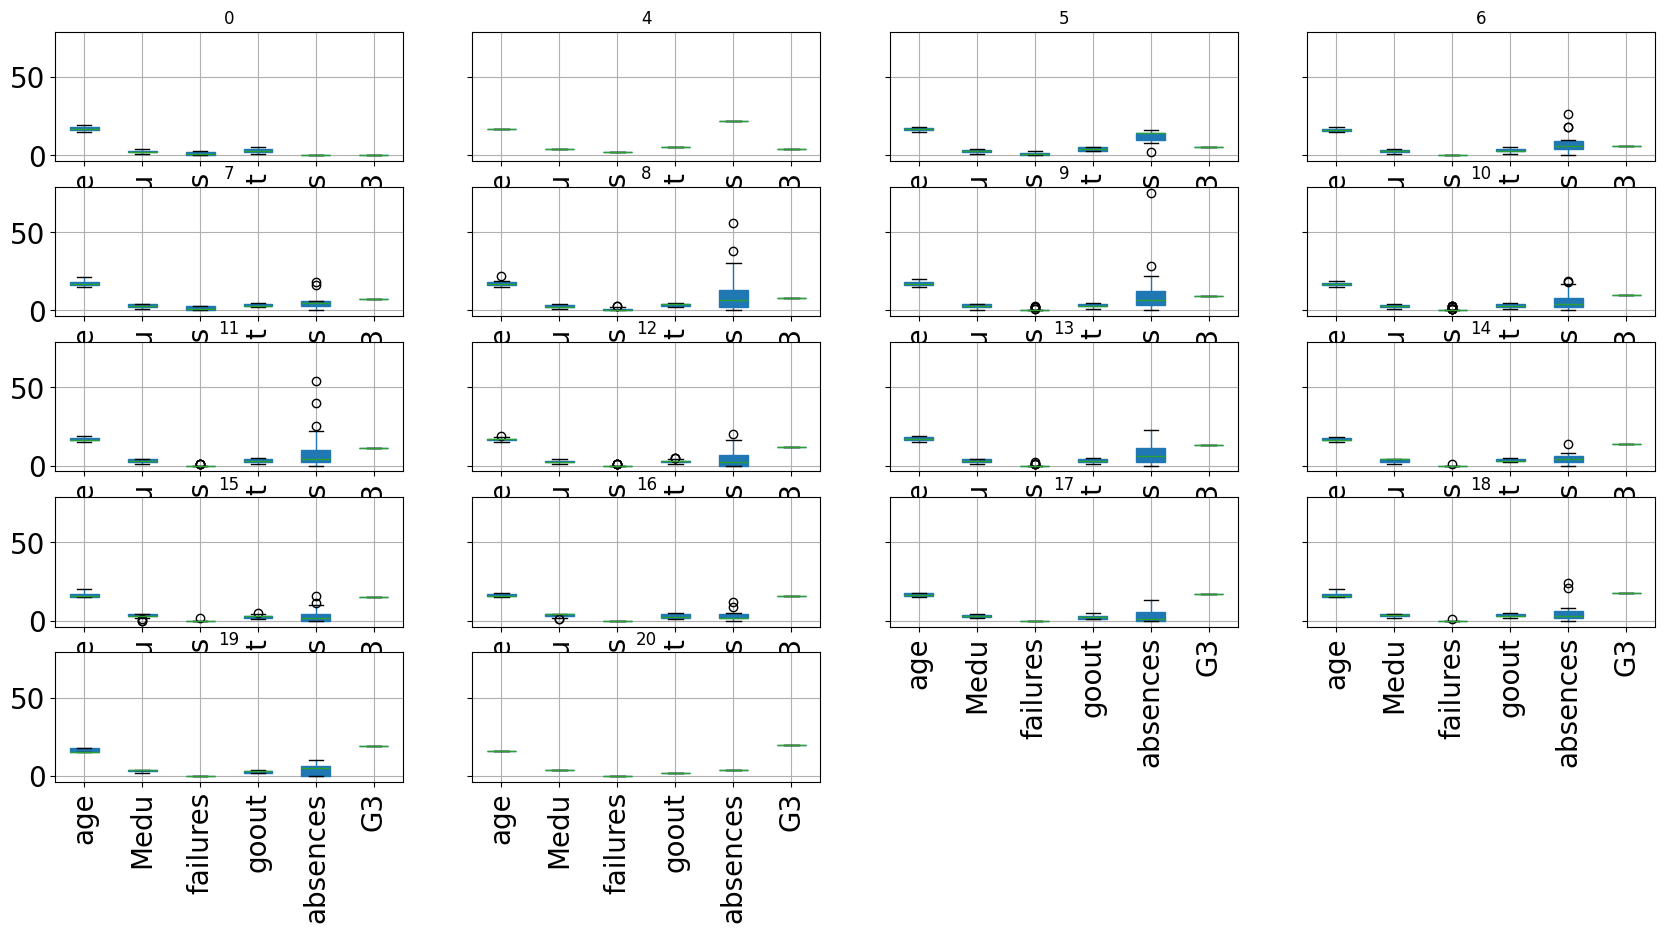

In [286]:
df.groupby('G3').boxplot(fontsize=20,rot=90,figsize=(20,10),patch_artist=True)

In [287]:
# Convert class column to numeric values
corr_matrix = df.corr(numeric_only=True)
corr_matrix["G3"].sort_values(ascending=False)

G3          1.000000
Medu        0.217147
absences    0.034247
goout      -0.132791
age        -0.161579
failures   -0.360415
Name: G3, dtype: float64

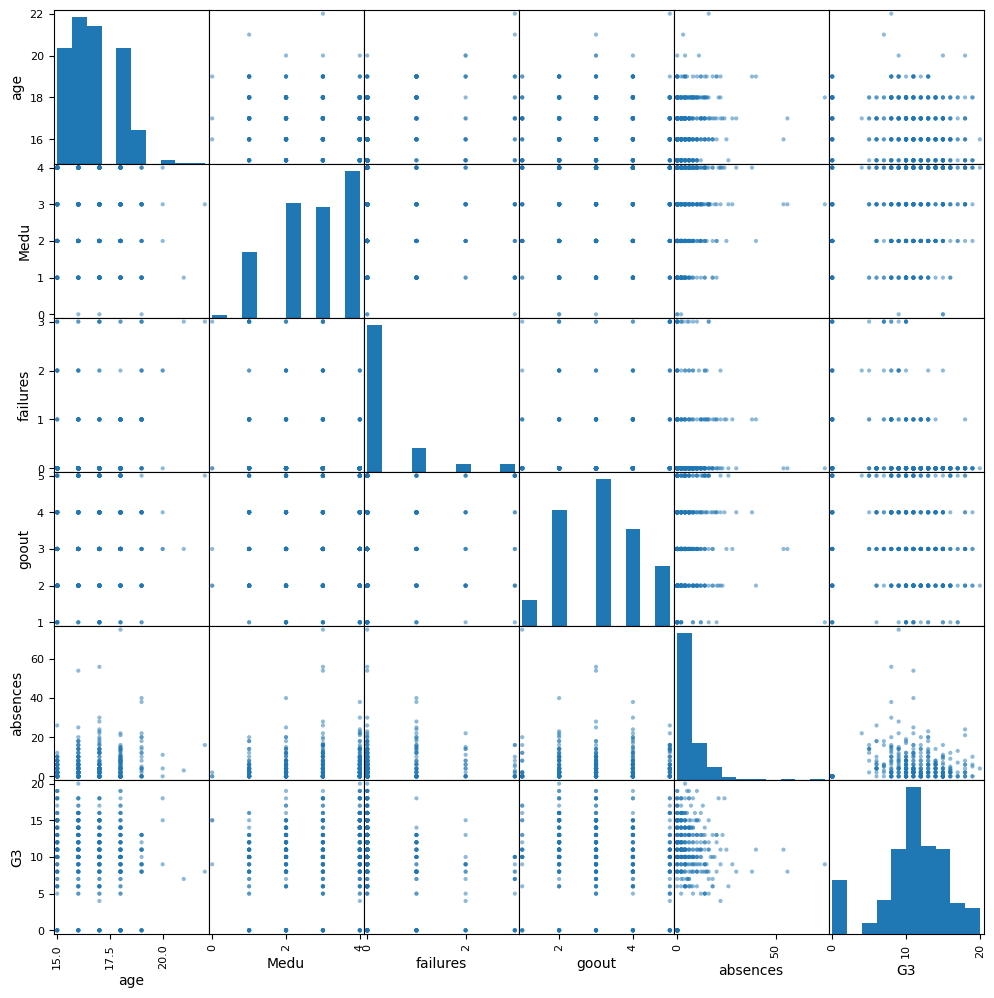

In [288]:
pd.plotting.scatter_matrix(df,figsize=(12,12))
plt.show()

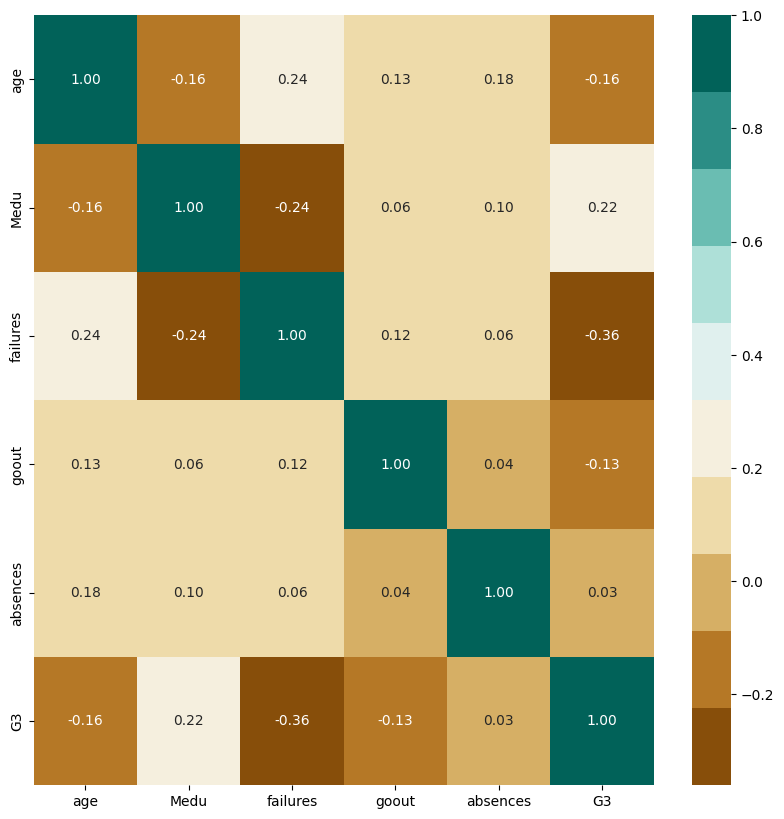

In [289]:
# Plot figsize
fig, ax = plt.subplots(figsize=(10, 10))
colormap = sns.color_palette("BrBG", 10)

sns.heatmap(corr_matrix, cmap=colormap, annot=True, fmt=".2f")
plt.show()

## Otroa valores

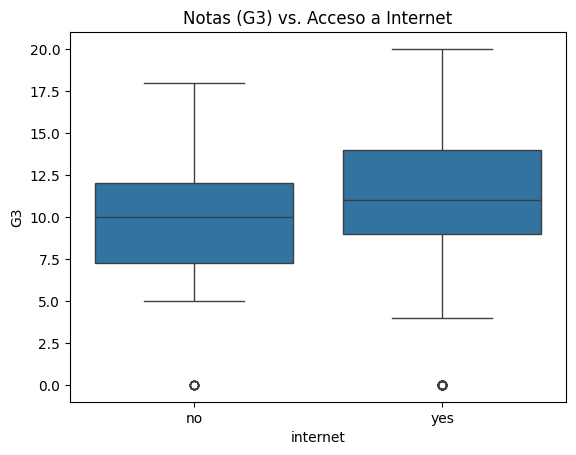

In [290]:
sns.boxplot(
    x='internet',  
    y='G3',       
    data=df,
    patch_artist=True 
)
plt.title('Notas (G3) vs. Acceso a Internet')
plt.show()

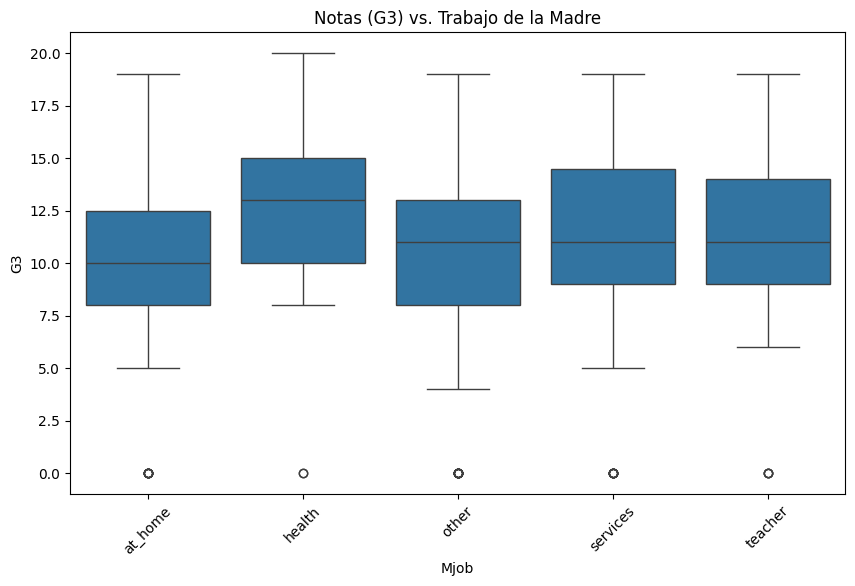

In [291]:
plt.figure(figsize=(10, 6)) 
sns.boxplot(
    x='Mjob',      
    y='G3',        
    data=df,
    patch_artist=True
)
plt.title('Notas (G3) vs. Trabajo de la Madre')
plt.xticks(rotation=45) 
plt.show()

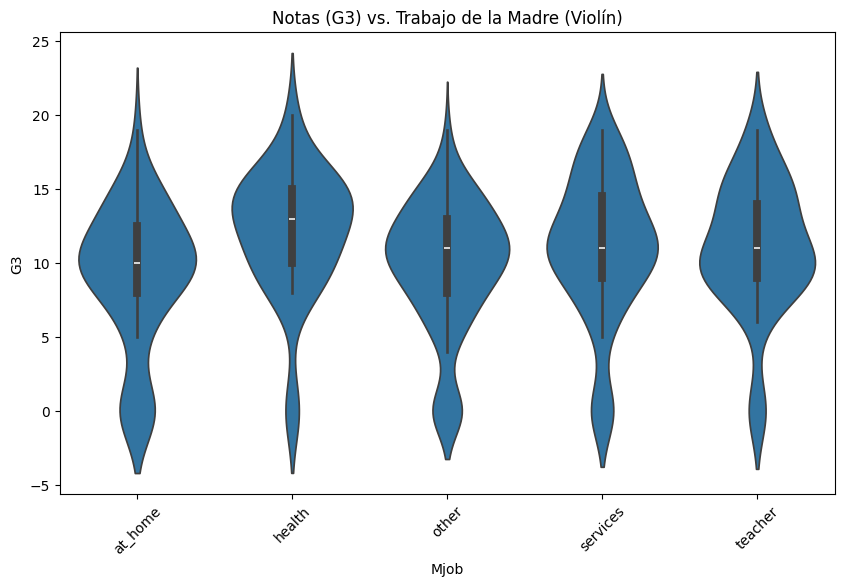

In [292]:
plt.figure(figsize=(10, 6))
sns.violinplot(
    x='Mjob',      
    y='G3',        
    data=df
)
plt.title('Notas (G3) vs. Trabajo de la Madre (Violín)')
plt.xticks(rotation=45)
plt.show()

# Congratulations!

You have completed this lab, and you can now end the lab by following the lab guide instructions.